# CFDT framework prototype — experiments notebook
**Towards a Software Engineering Framework for Cognitive Federated Digital Twins: Architecture, Adaptation, and Runtime Assurance** (DTWISE 2027 submission)

This notebook is the self-contained prototype and evaluation behind the paper. It implements, in simulation:

1. the **framework's component architecture** and design-level coupling metrics (Sect. 3),
2. a **museum emergency-response demonstrator**: four museums with local digital twins, a hazard (fire/flood) that spreads, limited outside assembly capacity, and a shared pool of emergency teams,
3. a **cognitive agent** (a *simulated* LLM agent whose outputs follow a fault taxonomy — no network access or API key is needed; a hook for a real LLM is provided but not used),
4. **federated coordination** with privacy-preserving summaries (quantised headroom + Laplace noise) and **hierarchical MAPE-K** adaptation,
5. a **runtime assurance layer**: schema/entity/policy checks, twin-based predictive validation, deterministic fallback, human escalation, synchronisation (staleness) monitoring.

**Important scope note.** The agent is a calibrated *stub*: when it is "correct" it returns the output of an oracle planner, and when it is "faulty" it returns one of five fault types at a configurable rate. The experiments therefore measure how the *architecture* contains agent faults and exploits federation — they do **not** measure the reliability of any real LLM.

Everything is seeded, needs only `numpy`, `scipy`, `pandas`, `matplotlib`, and runs in about 3 minutes (`QUICK = True` ≈ 30 s). Figures go to `figures/`, LaTeX tables and number macros to `tables/`.

In [2]:
import os, json, math, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

QUICK = False
SEED = 2027
FIG_DIR, TAB_DIR = "figures", "tables"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 6.5, "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "figure.dpi": 110, "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
PAL = {"gray": "#7f7f7f", "blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00", "purple": "#CC79A7", "sky": "#56B4E9"}
RESULTS = {}; T_START = time.time()

## 1. Framework architecture and design-level coupling metrics
The framework has seven components (Sect. 3 of the paper) that interact only through a message bus with schema-checked contracts, plus layered read-dependencies on the knowledge context.
As a *design-level* sanity check (not empirical evidence), we compare the dependency graph of the framework with a tightly coupled reference design in which components call each other directly (the typical shape of ad-hoc prototypes).
Metrics: number of dependencies, mean efferent coupling $C_e$, mean instability $I=C_e/(C_a+C_e)$, dependency cycles, and layer-skipping dependencies.

In [3]:
COMPONENTS = ["PhysicalEntity", "DataAcquisition", "LocalTwin", "KnowledgeContext", "CognitiveAgent", "FederatedCoordinator", "AdaptationController", "AssuranceMonitor", "MessageBus"]
LAYER = {"PhysicalEntity": 0, "DataAcquisition": 0, "LocalTwin": 1, "KnowledgeContext": 2, "CognitiveAgent": 3, "FederatedCoordinator": 3,
         "AdaptationController": 4, "AssuranceMonitor": 4, "MessageBus": -1}                    # -1 = cross-cutting infrastructure
FRAMEWORK = [("DataAcquisition", "PhysicalEntity"), ("LocalTwin", "DataAcquisition"), ("LocalTwin", "MessageBus"), ("KnowledgeContext", "LocalTwin"),
             ("CognitiveAgent", "KnowledgeContext"), ("CognitiveAgent", "MessageBus"), ("FederatedCoordinator", "MessageBus"), ("FederatedCoordinator", "KnowledgeContext"),
             ("AdaptationController", "MessageBus"), ("AdaptationController", "KnowledgeContext"), ("AssuranceMonitor", "MessageBus"), ("AssuranceMonitor", "KnowledgeContext")]
ADHOC = [("DataAcquisition", "PhysicalEntity"), ("LocalTwin", "DataAcquisition"), ("LocalTwin", "CognitiveAgent"), ("CognitiveAgent", "LocalTwin"), ("CognitiveAgent", "DataAcquisition"),
         ("CognitiveAgent", "FederatedCoordinator"), ("FederatedCoordinator", "LocalTwin"), ("FederatedCoordinator", "CognitiveAgent"), ("AdaptationController", "CognitiveAgent"),
         ("AdaptationController", "LocalTwin"), ("AdaptationController", "FederatedCoordinator"), ("AssuranceMonitor", "CognitiveAgent"), ("AssuranceMonitor", "LocalTwin"), ("KnowledgeContext", "CognitiveAgent"), ("KnowledgeContext", "LocalTwin")]

def arch_metrics(edges):
    ce = {c: 0 for c in COMPONENTS}; ca = {c: 0 for c in COMPONENTS}
    for a, b in edges: ce[a] += 1; ca[b] += 1
    inst = [ce[c] / (ce[c] + ca[c]) for c in COMPONENTS if ce[c] + ca[c] > 0 and c != "MessageBus"]
    adj = {c: [] for c in COMPONENTS}
    for a, b in edges: adj[a].append(b)
    cycles = set()
    def dfs(node, path):
        for nxt in adj[node]:
            if nxt in path:
                cyc = path[path.index(nxt):]; cycles.add(tuple(sorted(cyc)))
            else: dfs(nxt, path + [nxt])
    for c in COMPONENTS: dfs(c, [c])
    skips = sum(1 for a, b in edges if LAYER[b] >= 0 and LAYER[a] >= 0 and (LAYER[b] > LAYER[a] or LAYER[a] - LAYER[b] > 2))
    direct = sum(1 for a, b in edges if b != "MessageBus")
    return dict(dependencies=len(edges), direct_peer_calls=direct, mean_Ce=np.mean([ce[c] for c in COMPONENTS if c != "MessageBus"]), mean_instability=float(np.mean(inst)),
                cycles=len(cycles), layer_violations=skips)
ARCH = pd.DataFrame({"framework": arch_metrics(FRAMEWORK), "tightly coupled reference": arch_metrics(ADHOC)}).T
display(ARCH.round(2)); RESULTS["arch"] = {k: {m: float(v) for m, v in r.items()} for k, r in ARCH.iterrows()}

,dependencies,direct_peer_calls,mean_Ce,mean_instability,cycles,layer_violations
framework,12.0,7.0,1.50,0.67,0.0,0.0
tightly coupled reference,15.0,15.0,1.88,0.56,3.0,5.0


## 2. Museum emergency-response demonstrator (physical world, local twins, agent, assurance, federation)
*World.* Four museums ($M{=}4$), step = 10 s, horizon = 30 min. A hazard (fire/flood) starts at one museum and may cascade to a second; the hazard level grows linearly to 1; visitors still inside while level ≥ 0.5 accumulate **exposure**. Evacuation is limited by the museum's egress rate and by an *outside assembly capacity*; overflow can only be absorbed by **redirecting visitors to a partner museum** that has headroom and is not hazardous. Two **emergency teams** are shared across the federation and raise egress rate by 30 % when deployed (6 steps delay).
*Sensing and synchronisation.* Each local twin estimates hazard (noise σ = 0.02) and occupancy (5 % noise). In 35 % of scenarios the source museum's hazard sensor drops out around onset (hold-last estimate unless the sync monitor detects staleness and escalates to a human).
*Federation.* Every 30 s each twin publishes a **privacy-preserving summary** (hazard bin 0–3, headroom quantised to 10 % plus optional Laplace noise); raw occupancy is never shared. In 30 % of scenarios the federation link drops for 150–400 s.
*Agent.* Triggered when estimated hazard > 0.1; answers after a latency of ≥ 1 step with a plan `{intensity, redirect target+fraction, team request}`. With probability `p_err` the plan is faulty: *malformed*, *hallucinated entity* (non-existent shelter), *constraint-violating* (over-request/unsafe redirect), *inconsistent* (stale reasoning, too little evacuation) or *omission* (no answer).
*Assurance (R).* Schema & entity check, policy/constraint check against the twin's view, **twin-based predictive validation** (30-step look-ahead vs the deterministic fallback; reject if ratio > 1.5, escalate to a human if 1.2–1.5), watchdog timeout, staleness monitor, **admission control at the receiving twin**, deterministic fallback.
*Hierarchical MAPE-K (MP).* Per-museum monitor of the rejection rate (EWMA); above 0.3 the museum degrades to deterministic fallback mode (agent keeps running in shadow); recovers below 0.12.

In [4]:
M=4; DT=10.0; T=180                      # 4 museums, 10 s step, 30 min horizon
H_CRIT=0.5; H_NOGO=0.3; REPLAN=6; PUB_EVERY=3; POOL=2; TEAM_GAIN=0.3; TEAM_DELAY=6
MODES=["malformed","entity","constraint","inconsistent","omission"]; MODE_P=[.2,.2,.25,.25,.1]
NCALL=40

def gen_scenarios(n, seed):
    rng=np.random.default_rng(seed); out=[]
    for _ in range(n):
        n0=rng.integers(300,700,M).astype(float); cap=np.floor(n0*rng.uniform(1.25,1.7,M))
        s=dict(n0=n0,cap=cap,rho=rng.uniform(10,16,M),asm=np.floor(rng.uniform(0.45,1.1,M)*n0),src=int(rng.integers(M)),
               t_h=np.full(M,np.inf),tau=rng.integers(30,60,M).astype(float))
        s["t_h"][s["src"]]=rng.integers(8,30)
        if rng.random()<0.3:
            j=int((s["src"]+rng.integers(1,M))%M); s["t_h"][j]=s["t_h"][s["src"]]+rng.integers(8,25)
        s["drop"]=(int(s["t_h"][s["src"]]-2),int(s["t_h"][s["src"]]-2+rng.integers(8,19))) if rng.random()<0.35 else (0,0)
        s["link"]=(int(rng.integers(10,50)),0); s["link"]=(s["link"][0],s["link"][0]+int(rng.integers(15,41))) if rng.random()<0.3 else (0,0)
        s["hn"]=rng.normal(0,0.02,(T,M)); s["on"]=rng.normal(0,0.05,(T,M))
        s["U"]=rng.random((M,NCALL,6)); s["lap"]=rng.laplace(0,1,(T,M))
        out.append(s)
    return out

def hazard(s,t): return np.clip((t-s["t_h"])/s["tau"],0,1)

def rule_plan(est, pub, s, fed, thr, teams_ok):
    """Deterministic planner (also the verified fallback). est: dict with h, n; pub: federated view."""
    i=est["i"]; plan=dict(int=1.0 if est["h"]>thr else 0.0,tgt=None,frac=0.0,team=0)
    if plan["int"]>0 and fed:
        need=est["n"]-est["asm_free"]
        if need>0:
            best=None;bh=-1
            for j in range(M):
                if j!=i and pub["hb"][j]<=1 and pub["head"][j]>bh: best,bh=j,pub["head"][j]
            if best is not None and bh>0.05:
                plan["tgt"]=best; plan["frac"]=float(np.clip(min(need,max(bh*s["cap"][best],0))/max(est["n"],1),0,1))
        if teams_ok and est.get("can_team",True) and est["h"]>0.2: plan["team"]=1
    return plan

def predicted_remaining(plan,est,pub,s,i,H=30):
    out=s["rho"][i]*plan["int"]*(1+TEAM_GAIN*plan.get("team",0))*H
    cap_out=est["asm_free"]
    if plan["tgt"] is not None and 0<=plan["tgt"]<M: cap_out+=max(pub["head"][plan["tgt"]]*s["cap"][plan["tgt"]],0)*0.5+1e-9
    return max(est["n"]-min(out,cap_out+ (est["n"] if plan["tgt"] is None and plan["int"]>0 and False else 0)),0)

def agent_plan(est,pub,s,i,fed,u,p_err):
    """Simulated cognitive agent. Correct output = oracle planner (low threshold, may request a team); faulty outputs follow a fault taxonomy."""
    good=rule_plan(est,pub,s,fed,0.10,True); fault=None
    if u[0]<p_err:
        fault=MODES[int(np.searchsorted(np.cumsum(MODE_P),u[1]))]
        if fault=="malformed": return None,fault
        if fault=="omission": return "omit",fault
        pl=dict(good)
        if fault=="entity": pl["tgt"]=7; pl["frac"]=max(pl["frac"],0.5)           # non-existent shelter
        elif fault=="constraint":
            pl["team"]=3 if (u[2]<0.5 or not fed) else pl["team"]
            if fed: pl["tgt"]=int(np.argmin(pub["head"]+np.where(np.arange(M)==i,9,0))); pl["frac"]=1.0
            if pl["int"]==0: pl["int"]=1.0
        elif fault=="inconsistent": pl["int"]=0.0 if u[2]<0.5 else 0.5; pl["tgt"]=None; pl["frac"]=0.0   # stale-state reasoning
        return pl,fault
    return good,None

def run(s, cfg, rng_seed=0):
    """cfg: agent, assure, fed, mape, p_err, eps (None = no DP noise), thr (rule threshold)."""
    A,R,F,MP=cfg["agent"],cfg["assure"],cfg["fed"],cfg["mape"]; p_err=cfg["p_err"]; eps=cfg.get("eps",None)
    n=s["n0"].copy(); outside=np.zeros(M); teams=np.zeros(M); pool=POOL; team_due=[]
    plan=[dict(int=0.0,tgt=None,frac=0.0,team=0) for _ in range(M)]
    hest=np.zeros(M); lasth=np.zeros(M); age=np.zeros(M); human_fix=[None]*M
    pub=dict(hb=np.zeros(M),head=np.full(M,0.3)); pub_age=0; pend=[None]*M; nextplan=[0]*M; ncall=[0]*M
    ewma=np.zeros(M); degraded=np.zeros(M,bool); stats=dict(plans=0,faulty=0,flag_faulty=0,flag_ok=0,ok=0,valid_out=0,esc=0,violations=0,exposure=0.0,
        msgs=0,bytes=0,recon=[],lat=[],first_act=None,cleared=None,rej=0,host_degrade=0,sync_err=[],conflicts=0)
    src=s["src"]; t0=s["t_h"][src]; last_msg=None
    for t in range(T):
        h=hazard(s,t); nh=n*(1+s["on"][t])
        # ---------- sensing / local twin synchronisation ----------
        for i in range(M):
            dropped=(i==src and s["drop"][0]<=t<s["drop"][1])
            if not dropped: hest[i]=h[i]+s["hn"][t,i]; lasth[i]=hest[i]; age[i]=0; human_fix[i]=None
            else:
                age[i]+=1
                if R and age[i]>=3:                                   # sync monitor: staleness detected -> human verification
                    if human_fix[i] is None: human_fix[i]=t+3; stats["esc"]+=1
                    if t>=human_fix[i]: hest[i]=h[i]+s["hn"][t,i]
                    else: hest[i]=lasth[i]
                else: hest[i]=lasth[i]                               # hold-last (unmonitored)
            stats["sync_err"].append(abs(hest[i]-h[i]))
        # ---------- federation: privacy-preserving summaries ----------
        if F and t%PUB_EVERY==0:
            if not (s["link"][0]<=t<s["link"][1]):
                for i in range(M):
                    hb=int(np.clip(np.floor(hest[i]*4),0,3)); head=(s["cap"][i]-nh[i])/s["cap"][i]
                    head=np.round(head*10)/10
                    if eps is not None: head+=s["lap"][t,i]*(0.1/eps)
                    pub["hb"][i]=hb; pub["head"][i]=head
                    msg=json.dumps({"id":i,"t":t,"hz":hb,"hd":round(float(head),2)}); stats["msgs"]+=1; stats["bytes"]+=len(msg)
                    stats["recon"].append(abs(s["cap"][i]*(1-head)-n[i])/s["cap"][i])
                pub_age=0
            else: pub_age+=1
        else: pub_age+=1 if F else 0
        # ---------- decisions ----------
        for i in range(M):
            est=dict(i=i,h=hest[i],n=nh[i],asm_free=s["asm"][i]-outside[i],can_team=(teams[i]==0 and not any(x[1]==i for x in team_due)))
            if not A:                                                  # C0: rule-based, instantaneous
                plan[i]=rule_plan(est,pub,s,False,cfg.get("thr",0.3),False); continue
            if pend[i] is not None and t>=pend[i]["ready"]:
                p=pend[i]; pend[i]=None; pl,fault=p["plan"],p["fault"]
                stats["plans"]+=1; stats["faulty"]+= fault is not None; stats.setdefault("n_"+str(fault),0); stats["n_"+str(fault)]+=1; stats["ok"]+= fault is None; stats["valid_out"]+= (fault not in ("malformed",))
                flagged=False; humanrev=False; why=""
                if R:
                    if pl is None: flagged=True
                    elif pl=="omit": flagged=True; why="timeout"            # watchdog: no answer within deadline
                    else:
                        if pl["tgt"] is not None and not (0<=pl["tgt"]<M): flagged=True; why="entity"
                        elif pl["tgt"] is not None and (pub["hb"][pl["tgt"]]>=2 or pl["frac"]*est["n"]>max(pub["head"][pl["tgt"]]*s["cap"][pl["tgt"]],0)*1.1+5 or (F and pub_age>6)): flagged=True; why="constraint"
                        elif pl["team"]>POOL: flagged=True; why="team"
                        else:
                            fb=rule_plan(est,pub,s,F,0.20,False)
                            rp,rf=predicted_remaining(pl,est,pub,s,i),predicted_remaining(fb,est,pub,s,i)
                            ratio=(rp+1)/(rf+1)
                            if ratio>1.5: flagged=True; why="consistency"
                            elif ratio>1.2: humanrev=True
                    if flagged and fault is None: stats.setdefault("fp_"+why,0); stats["fp_"+why]+=1
                    if fault is not None: stats["flag_faulty"]+=(flagged or humanrev); stats.setdefault("f_"+fault,0); stats["f_"+fault]+=int(flagged or humanrev)
                    else: stats["flag_ok"]+=flagged; stats["esc_ok"]=stats.get("esc_ok",0)+int(humanrev)
                    if MP: ewma[i]=0.7*ewma[i]+0.3*(1.0 if flagged else 0.0)
                    if flagged:
                        stats["rej"]+=1; plan[i]=rule_plan(est,pub,s,F,0.20,False); stats["lat"].append(p["lat"]); continue
                    if humanrev:
                        stats["esc"]+=1; pend[i]=dict(plan=rule_plan(est,pub,s,F,0.10,True),fault=None,ready=t+2,lat=p["lat"]+2,reviewed=True); continue
                if pl is None or pl=="omit": continue                   # unassured: unparsable / no answer -> ignored
                plan[i]=pl; stats["lat"].append(p["lat"])
                if pl["team"]>POOL: stats["violations"]+=1                   # over-allocation request executed
                if pl["team"]>0 and pool>0 and est["can_team"]:
                    k=min(pl["team"],pool); team_due.append((t+TEAM_DELAY,i,k)); pool-=k
            # trigger a new agent call
            if pend[i] is None and t>=nextplan[i] and (est["h"]>0.10) and ncall[i]<NCALL:
                u=s["U"][i,ncall[i]]; ncall[i]+=1; nextplan[i]=t+REPLAN
                pl,fault=agent_plan(est,pub,s,i,F,u,p_err); lat=max(1,int(np.ceil(np.exp(np.log(0.8)+0.7*np.sqrt(2)*math.erf(2*u[3]-1)*0.7))))
                if MP and R and degraded[i]:
                    plan[i]=rule_plan(est,pub,s,F,0.20,False)               # degraded mode: deterministic, agent runs in shadow
                    stats["host_degrade"]+=1
                pend[i]=dict(plan=pl,fault=fault,ready=t+lat,lat=lat)
            if MP and R:
                if ewma[i]>0.3: degraded[i]=True
                elif ewma[i]<0.12 and degraded[i]: degraded[i]=False
            if MP and R and degraded[i]:
                plan[i]=rule_plan(est,pub,s,F,0.20,False)
        # teams arrive
        for (td,i,k) in list(team_due):
            if t>=td: teams[i]+=k; team_due.remove((td,i,k))
        # ---------- physical execution ----------
        d_in=np.zeros(M); 
        for i in range(M):
            pl=plan[i]
            if pl["int"]<=0 or n[i]<=0: continue
            desired=min(n[i],s["rho"][i]*pl["int"]*(1+TEAM_GAIN*teams[i])); r=0.0
            if pl["tgt"] is not None:
                if not (0<=pl["tgt"]<M): desired=0.0                    # hallucinated entity: execution error
                else:
                    j=pl["tgt"]; rdes=desired*pl["frac"]
                    if R:                                               # admission control by receiving twin
                        r=min(rdes,max(s["cap"][j]-n[j]-d_in[j],0)) if h[j]<H_NOGO else 0.0
                        if r<rdes: stats["conflicts"]+=1
                    else: r=rdes
                    if h[j]>=H_NOGO and r>0: stats["violations"]+=1
            asm_free=s["asm"][i]-outside[i]; out_o=min(desired-r,max(asm_free,0)); tot=r+out_o
            n[i]-=tot; outside[i]+=out_o
            if pl["tgt"] is not None and 0<=pl["tgt"]<M: d_in[pl["tgt"]]+=r
            if stats["first_act"] is None and i==src and t>=t0 and tot>0: stats["first_act"]=t
        n+=d_in
        for j in range(M):
            if n[j]>s["cap"][j]: stats["violations"]+=1
        stats["exposure"]+=float(np.sum(n*(h>=H_CRIT))*DT)
        if stats["cleared"] is None and t>=t0 and n[src]<0.05*s["n0"][src]: stats["cleared"]=t
    stats["conservation_err"]=float(abs(n.sum()+outside.sum()-s["n0"].sum()))
    stats["exposure"]/=s["n0"].sum()
    return stats


# LLM hook (not used here): replace agent_plan() by a function that prompts a real model with the twin/knowledge context and parses its JSON answer.
def llm_agent_hook(prompt: str) -> str:
    raise NotImplementedError("Plug a real LLM client here; the evaluation in this notebook uses the fault-injected stub agent_plan().")

## 3. Configurations
| id | agents | assurance | federation | MAPE-K |
|---|---|---|---|---|
| C0 | – (rule-based, threshold 0.3) | – | – | – |
| C1 | ✓ | – | – | – |
| C2 | ✓ | ✓ | – | – |
| C3 | ✓ | – | ✓ | – |
| C4 (**full CFDT**) | ✓ | ✓ | ✓ | ✓ |
| C5 | ✓ | ✓ | ✓ | – |

In [5]:
N_SC = 120 if QUICK else 300; N_SWEEP = 80 if QUICK else 200
CFG = {"C0": dict(agent=False, assure=False, fed=False, mape=False), "C1": dict(agent=True, assure=False, fed=False, mape=False),
       "C2": dict(agent=True, assure=True, fed=False, mape=False), "C3": dict(agent=True, assure=False, fed=True, mape=False),
       "C4": dict(agent=True, assure=True, fed=True, mape=True), "C5": dict(agent=True, assure=True, fed=True, mape=False)}
NAME = {"C0": "C0 Rule-based local", "C1": "C1 Agents", "C2": "C2 Agents + assurance", "C3": "C3 Agents + federation", "C4": "C4 Full CFDT", "C5": "C5 Full CFDT, no MAPE-K"}
SC = gen_scenarios(N_SC, SEED); SC_SW = SC[:N_SWEEP]
def evaluate(cfgname, scen, p_err=0.2, eps=None):
    return [run(s, {**CFG[cfgname], "p_err": p_err, "eps": eps, "thr": 0.3}) for s in scen]
def agg(rs, scen):
    ex = np.array([r["exposure"] for r in rs]); t0 = np.array([s["t_h"][s["src"]] for s in scen])
    fa = np.array([(r["first_act"] if r["first_act"] is not None else T) - t0[i] for i, r in enumerate(rs)]) * DT
    rc = np.array([(r["cleared"] if r["cleared"] is not None else T) - t0[i] for i, r in enumerate(rs)]) * DT
    lat = np.array([np.mean(r["lat"]) if r["lat"] else np.nan for r in rs]) * DT
    nf, nfl = sum(r["faulty"] for r in rs), sum(r["flag_faulty"] for r in rs); nok, nfo = sum(r["ok"] for r in rs), sum(r["flag_ok"] for r in rs)
    return dict(exp=ex, viol=np.array([r["violations"] for r in rs], float), adapt=fa, recov=rc, lat=lat,
                det=nfl / nf if nf else np.nan, fpr=nfo / nok if nok else np.nan, valid=(sum(r["valid_out"] for r in rs) / max(sum(r["plans"] for r in rs), 1)),
                sync=np.mean([np.sqrt(np.mean(np.square(r["sync_err"]))) for r in rs]), esc=np.mean([r["esc"] for r in rs]), rej=np.mean([r["rej"] for r in rs]),
                msgs=np.mean([r["msgs"] for r in rs]), bytes=np.mean([r["bytes"] for r in rs]), conflicts=np.mean([r["conflicts"] for r in rs]))
def ci_mean(x, B=1000, seed=1):
    r = np.random.default_rng(seed); x = np.asarray(x); m = [np.mean(x[r.integers(0, len(x), len(x))]) for _ in range(B)]
    return float(np.mean(x)), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

## 4. E1 — configuration comparison (agent fault rate 0.2)

In [6]:
t0 = time.time(); E1R = {}; E1RAW = {}
for k in CFG: E1RAW[k] = evaluate(k, SC); E1R[k] = agg(E1RAW[k], SC)
rows = []
for k in CFG:
    a = E1R[k]; e = ci_mean(a["exp"])
    rows.append({"config": NAME[k], "exposure s/visitor": e[0], "CI lo": e[1], "CI hi": e[2], "violations/scenario": a["viol"].mean(), "adaptation s": np.nanmean(a["adapt"]),
                 "recovery s": np.nanmean(a["recov"]), "decision latency s": np.nanmean(a["lat"]), "detection %": 100 * a["det"], "false-positive %": 100 * a["fpr"]})
E1 = pd.DataFrame(rows).set_index("config"); display(E1.round(2)); print(f"E1: {time.time()-t0:.0f}s")
RESULTS["E1"] = {k: dict(exp=ci_mean(E1R[k]["exp"]), viol=float(E1R[k]["viol"].mean()), adapt=float(np.nanmean(E1R[k]["adapt"])), recov=float(np.nanmean(E1R[k]["recov"])),
                         lat=float(np.nanmean(E1R[k]["lat"])), det=float(E1R[k]["det"]), fpr=float(E1R[k]["fpr"]), sync=float(E1R[k]["sync"]), esc=float(E1R[k]["esc"]),
                         rej=float(E1R[k]["rej"]), valid=float(E1R[k]["valid"]), msgs=float(E1R[k]["msgs"]), bytes=float(E1R[k]["bytes"]), conflicts=float(E1R[k]["conflicts"])) for k in CFG}

# paired differences (same scenarios): federation and assurance effects
def paired(a, b, B=1000, seed=3):
    r = np.random.default_rng(seed); d = np.asarray(a) - np.asarray(b); m = [np.mean(d[r.integers(0, len(d), len(d))]) for _ in range(B)]
    return float(np.mean(d)), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))
RESULTS["paired"] = {"C4_vs_C0": paired(E1R["C4"]["exp"], E1R["C0"]["exp"]), "C4_vs_C2": paired(E1R["C4"]["exp"], E1R["C2"]["exp"]), "C2_vs_C1": paired(E1R["C2"]["exp"], E1R["C1"]["exp"]),
                     "C1_vs_C0": paired(E1R["C1"]["exp"], E1R["C0"]["exp"]), "C4_vs_C5": paired(E1R["C4"]["exp"], E1R["C5"]["exp"]), "C3_vs_C4": paired(E1R["C3"]["exp"], E1R["C4"]["exp"])}
print({k: tuple(round(x, 2) for x in v) for k, v in RESULTS["paired"].items()})

C:\Users\HP\AppData\Local\Temp\ipykernel_1500\2488110775.py:7: RuntimeWarning: Mean of empty slice
  "recovery s": np.nanmean(a["recov"]), "decision latency s": np.nanmean(a["lat"]), "detection %": 100 * a["det"], "false-positive %": 100 * a["fpr"]})


,exposure s/visitor,CI lo,CI hi,violations/scenario,adaptation s,recovery s,decision latency s,detection %,false-positive %
config,,,,,,,,,
C0 Rule-based local,124.26,114.75,133.08,0.00,139.83,1341.97,NaN,NaN,NaN
C1 Agents,119.11,109.59,128.13,1.65,90.90,1327.47,13.54,0.00,0.00
C2 Agents + assurance,115.51,105.99,124.39,0.00,73.87,1325.20,13.54,78.82,0.00
C3 Agents + federation,27.89,25.06,31.10,18.39,90.90,414.63,13.54,0.00,0.00
C4 Full CFDT,24.73,21.62,28.13,0.00,79.67,404.30,13.54,70.38,4.72
"C5 Full CFDT, no MAPE-K",24.94,21.83,28.39,0.00,80.03,405.47,13.54,70.48,4.67


C:\Users\HP\AppData\Local\Temp\ipykernel_1500\2488110775.py:10: RuntimeWarning: Mean of empty slice
  lat=float(np.nanmean(E1R[k]["lat"])), det=float(E1R[k]["det"]), fpr=float(E1R[k]["fpr"]), sync=float(E1R[k]["sync"]), esc=float(E1R[k]["esc"]),


E1: 12s
{'C4_vs_C0': (-99.53, -106.65, -92.8), 'C4_vs_C2': (-90.78, -98.05, -84.0), 'C2_vs_C1': (-3.6, -4.69, -2.53), 'C1_vs_C0': (-5.15, -6.31, -3.93), 'C4_vs_C5': (-0.21, -0.34, -0.09), 'C3_vs_C4': (3.16, 1.55, 4.58)}


## 5. E2 — sweep of the agent fault rate

In [7]:
t0 = time.time(); PERR = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]; SW = {k: {"exp": [], "lo": [], "hi": [], "viol": []} for k in CFG}
for pe in PERR:
    for k in CFG:
        a = agg(evaluate(k, SC_SW, p_err=pe), SC_SW); m = ci_mean(a["exp"], B=300)
        SW[k]["exp"].append(m[0]); SW[k]["lo"].append(m[1]); SW[k]["hi"].append(m[2]); SW[k]["viol"].append(float(a["viol"].mean()))
print(f"E2: {time.time()-t0:.0f}s"); RESULTS["sweep"] = {"p_err": PERR, **{k: v for k, v in SW.items()}}
display(pd.DataFrame({k: SW[k]["exp"] for k in CFG}, index=PERR).round(1))

E2: 56s


,C0,C1,C2,C3,C4,C5
0.0,121.7,113.9,111.1,22.9,22.3,22.5
0.1,121.7,114.7,111.7,24.8,23.1,23.3
0.2,121.7,116.3,112.6,27.5,24.3,24.5
0.3,121.7,118.1,113.4,31.2,25.1,25.4
0.5,121.7,124.7,115.0,43.0,27.5,27.9
0.7,121.7,132.1,116.2,57.8,29.6,30.0
0.9,121.7,147.2,117.9,86.5,34.1,34.5


## 6. E3 — privacy–utility trade-off of federated summaries
The adversary is the coordinator (or a peer) that reconstructs a museum's true occupancy from published headroom, assuming public capacity. Error is reported as a fraction of capacity. Per-message ε-DP noise is Laplace with scale 0.1/ε on the 10 %-quantised headroom (ε = ∞ means no noise). The raw-sharing baseline publishes all local state fields every step.

In [8]:
t0 = time.time(); EPSL = [None, 5, 1, 0.5, 0.2, 0.1]; PRIV = []
for e in EPSL:
    rs = evaluate("C4", SC, eps=e); a = agg(rs, SC)
    rec = np.mean([np.mean(r["recon"]) for r in rs if r["recon"]])
    PRIV.append(dict(eps=("inf" if e is None else e), recon=float(rec), exposure=float(a["exp"].mean()), conflicts=float(a["conflicts"]), rej=float(a["rej"]), bytes=float(a["bytes"])))
PRIV = pd.DataFrame(PRIV); display(PRIV.round(3)); print(f"E3: {time.time()-t0:.0f}s")
LOCAL_FIELDS = ["occupancy", "occupancy_by_zone", "hazard_level", "sensor_readings", "sensor_health", "staff_roster", "visitor_ids", "ticketing", "collection_inventory", "camera_feeds", "plan_state", "resource_state"]
SHARED_FIELDS = ["hazard_bin", "headroom_q"]
raw_msg = json.dumps({f: 0.0 for f in LOCAL_FIELDS}); sum_msg = json.dumps({"id": 0, "t": 0, "hz": 0, "hd": 0.0})
RESULTS["privacy"] = dict(table=PRIV.to_dict("list"), field_exposure_raw=1.0, field_exposure_summary=len(SHARED_FIELDS) / len(LOCAL_FIELDS),
                          bytes_raw_per_scenario=float(len(raw_msg) * T * M), bytes_summary=float(PRIV["bytes"].iloc[0]), msgs_raw=float(T * M))

,eps,recon,exposure,conflicts,rej,bytes
0,inf,0.029,24.727,4.853,5.927,8746.647
1,5,0.038,24.606,4.843,5.993,8923.710
2,1,0.106,24.709,5.710,6.180,8958.240
3,0.5,0.202,24.902,6.057,6.383,8975.300
4,0.2,0.498,25.335,6.380,6.623,9004.753
5,0.1,0.995,25.546,6.753,6.700,9026.313


E3: 16s


## 7. E4 — federated model coordination (FedAvg) with noisy aggregation
Each museum learns a linear model of its egress throughput from local observations (heterogeneous coefficients). We compare local-only training, FedAvg (5 local gradient steps per round, weighted averaging) with Gaussian noise added to the aggregate, and a centralised pooled fit. Communication = rounds × museums × 2 directions × parameters × 8 bytes.

In [9]:
def fedavg_trial(seed, sigma, rounds=30, n_loc=40):
    r = np.random.default_rng(seed); w_true = np.array([1.0, 0.5]); X = []; Y = []
    for i in range(M):
        wi = w_true + r.normal(0, 0.08, 2); x = np.c_[np.ones(n_loc), r.uniform(0, 3, n_loc)]; X.append(x); Y.append(x @ wi + r.normal(0, 0.3, n_loc))
    xt = np.c_[np.ones(400), r.uniform(0, 3, 400)]; yt = np.vstack([xt @ (w_true + r.normal(0, 0.08, 2)) for _ in range(1)]).ravel() + r.normal(0, 0.3, 400)
    mse = lambda w: float(np.mean((xt @ w - yt) ** 2))
    cen = np.linalg.lstsq(np.vstack(X), np.concatenate(Y), rcond=None)[0]
    loc = np.mean([mse(np.linalg.lstsq(X[i], Y[i], rcond=None)[0]) for i in range(M)])
    w = np.zeros(2); curve = []
    for _ in range(rounds):
        ws = []
        for i in range(M):
            wi = w.copy()
            for _ in range(5): wi -= 0.1 * (2 / n_loc) * X[i].T @ (X[i] @ wi - Y[i])
            ws.append(wi)
        w = np.mean(ws, 0) + r.normal(0, sigma, 2); curve.append(mse(w))
    return np.array(curve), mse(cen), loc
SIG = [0.0, 0.02, 0.05, 0.1]; FED = {}
for sg in SIG:
    cs, ce, lo = zip(*[fedavg_trial(SEED + t, sg) for t in range(30)]); FED[sg] = dict(curve=np.mean(cs, 0), cen=float(np.mean(ce)), loc=float(np.mean(lo)))
cen, loc = FED[0.0]["cen"], FED[0.0]["loc"]
conv = {sg: int(next((i + 1 for i, v in enumerate(FED[sg]["curve"]) if v <= 1.05 * cen), 30)) for sg in SIG}
bytes_round = M * 2 * 2 * 8
RESULTS["fedavg"] = dict(cen=cen, loc=loc, final={str(sg): float(FED[sg]["curve"][-1]) for sg in SIG}, rounds_to_conv={str(sg): conv[sg] for sg in SIG}, bytes_per_round=bytes_round,
                         bytes_to_conv={str(sg): conv[sg] * bytes_round for sg in SIG})
print("centralised MSE %.3f | local-only MSE %.3f" % (cen, loc)); print("rounds to within 5%% of centralised:", conv); print("final MSE:", {sg: round(FED[sg]["curve"][-1], 3) for sg in SIG})

centralised MSE 0.119 | local-only MSE 0.145
rounds to within 5%% of centralised: {0.0: 7, 0.02: 7, 0.05: 7, 0.1: 30}
final MSE: {0.0: np.float64(0.119), 0.02: np.float64(0.122), 0.05: np.float64(0.136), 0.1: np.float64(0.179)}


## 8. E5 — runtime assurance: detection by fault type (agent fault rate 0.3, full CFDT)

In [10]:
rs = evaluate("C4", SC, p_err=0.3)
DET = {m: (sum(r.get("f_" + m, 0) for r in rs), sum(r.get("n_" + m, 0) for r in rs)) for m in MODES}
DETR = {m: (a / b if b else float("nan")) for m, (a, b) in DET.items()}
fp = sum(r["flag_ok"] for r in rs) / sum(r["ok"] for r in rs); esc_ok = sum(r.get("esc_ok", 0) for r in rs) / sum(r["ok"] for r in rs)
print({m: round(v, 2) for m, v in DETR.items()}, "| false-positive rate %.3f | unnecessary escalation rate %.4f" % (fp, esc_ok))
RESULTS["detect"] = dict(by_type={m: DETR[m] for m in MODES}, counts={m: DET[m] for m in MODES}, overall=sum(a for a, b in DET.values()) / sum(b for a, b in DET.values()), fpr=fp, esc_ok=esc_ok)

{'malformed': 1.0, 'entity': 1.0, 'constraint': 0.62, 'inconsistent': 0.19, 'omission': 1.0} | false-positive rate 0.048 | unnecessary escalation rate 0.0007


## 8b. Self-tests
Invariants that must hold for the simulator and the metrics. The notebook stops with an assertion error if any of them fails.

In [11]:
def _no_hazard(s): t = dict(s); t["t_h"] = np.full(M, np.inf); t["drop"] = (0, 0); return t
_c = lambda k: {**CFG[k], "p_err": 0.0, "eps": None, "thr": 0.3}
tests = {}
tests["visitors are conserved in every E1 run"] = max(r["conservation_err"] for k in E1RAW for r in E1RAW[k]) < 1e-6
tests["exposure lies in [0, horizon]"] = all(0 <= r["exposure"] <= T * DT for k in E1RAW for r in E1RAW[k])
tests["re-running a configuration is deterministic"] = np.allclose([run(s, {**CFG["C4"], "p_err": 0.2, "eps": None, "thr": 0.3})["exposure"] for s in SC[:10]], [r["exposure"] for r in E1RAW["C4"][:10]])
_nh = [run(_no_hazard(s), {**CFG[k], "p_err": 0.5, "eps": None, "thr": 0.3}) for s in SC[:20] for k in CFG]
tests["no hazard -> zero exposure, zero violations, no agent plans (all configs)"] = all(r["exposure"] == 0 and r["violations"] == 0 and r["plans"] == 0 for r in _nh)
tests["doubling egress rate does not raise mean exposure (C0)"] = np.mean([run(dict(s, rho=2 * s["rho"]), _c("C0"))["exposure"] for s in SC[:100]]) <= np.mean([run(s, _c("C0"))["exposure"] for s in SC[:100]])
tests["assured configurations execute no policy violations at any fault rate"] = all(max(SW[k]["viol"]) == 0 for k in ["C2", "C4", "C5"])
tests["valid-output rate matches the injected malformed rate (C1, p=0.2 -> 0.96)"] = abs(E1R["C1"]["valid"] - 0.96) < 0.02
tests["coupling check finds cycles only in the tightly coupled design"] = RESULTS["arch"]["framework"]["cycles"] == 0 and RESULTS["arch"]["tightly coupled reference"]["cycles"] > 0
for k, v in tests.items(): print(("PASS  " if v else "FAIL  ") + k)
assert all(tests.values()), "self-test failed"
RESULTS["selftests_passed"] = int(sum(tests.values())); RESULTS["selftests_total"] = len(tests)

PASS  visitors are conserved in every E1 run
PASS  exposure lies in [0, horizon]
PASS  re-running a configuration is deterministic
PASS  no hazard -> zero exposure, zero violations, no agent plans (all configs)
PASS  doubling egress rate does not raise mean exposure (C0)
PASS  assured configurations execute no policy violations at any fault rate
PASS  valid-output rate matches the injected malformed rate (C1, p=0.2 -> 0.96)
PASS  coupling check finds cycles only in the tightly coupled design


## 9. Figure and LaTeX exports

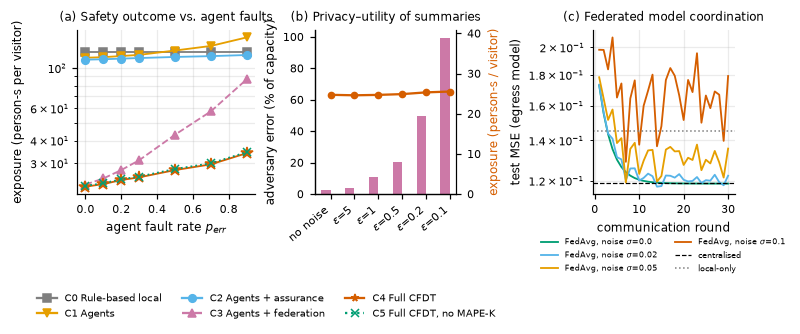

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(7.16, 2.5), constrained_layout=True, gridspec_kw={"width_ratios": [1.25, 1, 1]})
sty = {"C0": (PAL["gray"], "s", "-"), "C1": (PAL["orange"], "v", "-"), "C2": (PAL["sky"], "o", "-"), "C3": (PAL["purple"], "^", "--"), "C4": (PAL["red"], "*", "-"), "C5": (PAL["green"], "x", ":")}
a = ax[0]
for k in CFG:
    c, m, ls = sty[k]; a.plot(PERR, SW[k]["exp"], ls=ls, color=c, marker=m, ms=5 if k != "C4" else 8, lw=1.2, label=NAME[k])
a.set_xlabel("agent fault rate $p_{err}$"); a.set_ylabel("exposure (person-s per visitor)"); a.set_yscale("log"); a.grid(alpha=.25, which="both"); a.set_title("(a) Safety outcome vs. agent faults")
a = ax[1]; x = np.arange(len(PRIV)); a.bar(x - 0.2, 100 * PRIV["recon"], 0.4, color=PAL["purple"], label="occupancy reconstruction error (% of capacity)")
a.set_xticks(x); a.set_xticklabels([("no noise" if e == "inf" else f"$\\epsilon$={e}") for e in PRIV["eps"]], rotation=40, ha="right"); a.set_ylabel("adversary error (% of capacity)")
a2 = a.twinx(); a2.plot(x, PRIV["exposure"], "-o", color=PAL["red"], ms=4, label="exposure"); a2.set_ylabel("exposure (person-s / visitor)", color=PAL["red"]); a2.spines["right"].set_visible(True)
a2.set_ylim(0, max(PRIV["exposure"]) * 1.6); a.set_title("(b) Privacy–utility of summaries")
a = ax[2]
for sg, c in zip(SIG, [PAL["green"], PAL["sky"], PAL["orange"], PAL["red"]]): a.plot(range(1, 31), FED[sg]["curve"], color=c, lw=1.2, label=f"FedAvg, noise $\\sigma$={sg}")
a.axhline(cen, color="k", ls="--", lw=.8, label="centralised"); a.axhline(loc, color=PAL["gray"], ls=":", lw=1, label="local-only")
a.set_xlabel("communication round"); a.set_ylabel("test MSE (egress model)"); a.set_yscale("log"); a.legend(frameon=False, fontsize=5.5, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2); a.set_title("(c) Federated model coordination"); a.grid(alpha=.25, which="both")
from matplotlib.lines import Line2D
fig.legend([Line2D([0], [0], color=sty[k][0], ls=sty[k][2], marker=sty[k][1], ms=5) for k in CFG], [NAME[k] for k in CFG], loc="lower center", ncol=3, frameon=False, fontsize=6.5, bbox_to_anchor=(0.33, -0.17))
plt.savefig(os.path.join(FIG_DIR, "fig_results.pdf")); plt.show()

In [13]:
def fm(t): return f"{t[0]:.1f}"
lines = ["\\begin{tabular}{@{}lrrrrrrr@{}}", "\\toprule",
         "\\textbf{Configuration} & \\textbf{Exposure} \\textit{(95\\% CI)} & \\textbf{Viol.} & \\textbf{Adapt.\\ (s)} & \\textbf{Recov.\\ (s)} & \\textbf{Latency (s)} & \\textbf{Detect.\\ \\%} & \\textbf{FP \\%} \\\\", "\\midrule"]
for k in CFG:
    r = RESULTS["E1"][k]; e = r["exp"]
    det = "--" if r["det"] != r["det"] or not CFG[k]["assure"] else f"{100*r['det']:.0f}"; fpv = "--" if not CFG[k]["assure"] or r["fpr"] != r["fpr"] else f"{100*r['fpr']:.1f}"
    lat = "--" if r["lat"] != r["lat"] else f"{r['lat']:.0f}"
    nm = NAME[k].replace("C4 Full CFDT", "\\textbf{C4 Full CFDT}")
    lines.append(f"{nm} & {e[0]:.1f} ({e[1]:.1f}--{e[2]:.1f}) & {r['viol']:.1f} & {r['adapt']:.0f} & {r['recov']:.0f} & {lat} & {det} & {fpv} \\\\")
lines += ["\\bottomrule", "\\end{tabular}"]; open(os.path.join(TAB_DIR, "tab_results.tex"), "w").write("\n".join(lines))
A = RESULTS["arch"]
al = ["\\begin{tabular}{@{}lrr@{}}", "\\toprule", "\\textbf{Design-level metric} & \\textbf{Framework} & \\textbf{Tightly coupled} \\\\", "\\midrule"]
for lab, key, f in [("Dependencies", "dependencies", "{:.0f}"), ("Direct peer-to-peer calls", "direct_peer_calls", "{:.0f}"), ("Mean efferent coupling $C_e$", "mean_Ce", "{:.2f}"),
                    ("Mean instability $I$", "mean_instability", "{:.2f}"), ("Dependency cycles", "cycles", "{:.0f}"), ("Layer violations", "layer_violations", "{:.0f}")]:
    al.append(f"{lab} & {f.format(A['framework'][key])} & {f.format(A['tightly coupled reference'][key])} \\\\")
al += ["\\bottomrule", "\\end{tabular}"]; open(os.path.join(TAB_DIR, "tab_arch.tex"), "w").write("\n".join(al))

Mc = {}
def mac(n, v): Mc[n] = v
E = RESULTS["E1"]; P = RESULTS["paired"]
for k in CFG:
    mac(f"exp{k}", f"{E[k]['exp'][0]:.1f}"); mac(f"viol{k}", f"{E[k]['viol']:.1f}"); mac(f"adapt{k}", f"{E[k]['adapt']:.0f}"); mac(f"recov{k}", f"{E[k]['recov']:.0f}")
    mac(f"expLo{k}", f"{E[k]['exp'][1]:.1f}"); mac(f"expHi{k}", f"{E[k]['exp'][2]:.1f}")
mac("detOverall", f"{100*E['C4']['det']:.0f}"); mac("fprFull", f"{100*E['C4']['fpr']:.1f}"); mac("latFull", f"{E['C4']['lat']:.0f}")
mac("pairedFullVsRule", f"{-P['C4_vs_C0'][0]:.1f}"); mac("pairedAssure", f"{-P['C2_vs_C1'][0]:.1f}"); mac("pairedAgent", f"{-P['C1_vs_C0'][0]:.1f}")
mac("pairedMapeLo", f"{P['C4_vs_C5'][1]:.2f}"); mac("pairedMapeHi", f"{P['C4_vs_C5'][2]:.2f}"); mac("pairedMape", f"{P['C4_vs_C5'][0]:.2f}")
mac("reductionFull", f"{100*(1-E['C4']['exp'][0]/E['C0']['exp'][0]):.0f}"); mac("reductionFed", f"{100*(1-E['C3']['exp'][0]/E['C1']['exp'][0]):.0f}")
for m in MODES: mac(f"det{m.capitalize()}", f"{100*RESULTS['detect']['by_type'][m]:.0f}")
mac("detAt", f"{100*RESULTS['detect']['overall']:.0f}"); mac("fprAt", f"{100*RESULTS['detect']['fpr']:.1f}")
mac("syncC1", f"{E['C1']['sync']:.3f}"); mac("syncFull", f"{E['C4']['sync']:.3f}"); mac("escFull", f"{E['C4']['esc']:.1f}")
mac("c3viol", f"{E['C3']['viol']:.1f}"); mac("c3exp", f"{E['C3']['exp'][0]:.1f}")
sw = RESULTS["sweep"]; i9 = PERR.index(0.9); i5 = PERR.index(0.5)
mac("swC1At5", f"{sw['C1']['exp'][i5]:.1f}"); mac("swC3At9", f"{sw['C3']['exp'][i9]:.1f}"); mac("swC4At9", f"{sw['C4']['exp'][i9]:.1f}"); mac("swC5At9", f"{sw['C5']['exp'][i9]:.1f}")
mac("swC4At0", f"{sw['C4']['exp'][0]:.1f}"); mac("swC3At0", f"{sw['C3']['exp'][0]:.1f}"); mac("swC3violAt0", f"{sw['C3']['viol'][0]:.1f}"); mac("swC3violAt9", f"{sw['C3']['viol'][i9]:.1f}")
mac("swCOneAtNine", f"{sw['C1']['exp'][i9]:.1f}"); mac("swCTwoAtNine", f"{sw['C2']['exp'][i9]:.1f}"); mac("swMaxViolC4", f"{max(sw['C4']['viol']):.1f}"); mac("swC4At5", f"{sw['C4']['exp'][i5]:.1f}"); mac("swC0", f"{sw['C0']['exp'][0]:.1f}")
pv = RESULTS["privacy"]; mac("reconNone", f"{100*PRIV['recon'].iloc[0]:.1f}"); mac("reconOne", f"{100*PRIV['recon'].iloc[2]:.1f}"); mac("reconTenth", f"{100*PRIV['recon'].iloc[5]:.1f}")
mac("privExpNone", f"{PRIV['exposure'].iloc[0]:.1f}"); mac("privExpOne", f"{PRIV['exposure'].iloc[2]:.1f}"); mac("privExpTenth", f"{PRIV['exposure'].iloc[5]:.1f}")
mac("fieldShare", f"{100*pv['field_exposure_summary']:.0f}"); mac("bytesSumm", f"{pv['bytes_summary']/1000:.1f}"); mac("bytesRaw", f"{pv['bytes_raw_per_scenario']/1000:.0f}")
mac("bytesRatio", f"{pv['bytes_raw_per_scenario']/max(pv['bytes_summary'],1):.0f}"); mac("msgsFed", f"{E['C4']['msgs']:.0f}")
fa = RESULTS["fedavg"]; mac("fedCen", f"{fa['cen']:.3f}"); mac("fedLoc", f"{fa['loc']:.3f}"); mac("fedConv", f"{fa['rounds_to_conv']['0.0']}"); mac("fedConvNoisy", f"{fa['rounds_to_conv']['0.05']}")
mac("fedFinalNoisy", f"{fa['final']['0.05']:.3f}"); mac("fedBytes", f"{fa['bytes_to_conv']['0.0']}")
for key, lab in [("dependencies", "Deps"), ("direct_peer_calls", "Direct"), ("mean_instability", "Inst"), ("cycles", "Cyc"), ("layer_violations", "Lay")]:
    mac(f"arch{lab}Fw", f"{A['framework'][key]:.0f}" if key != "mean_instability" else f"{A['framework'][key]:.2f}"); mac(f"arch{lab}Adhoc", f"{A['tightly coupled reference'][key]:.0f}" if key != "mean_instability" else f"{A['tightly coupled reference'][key]:.2f}")
mac("nScen", f"{N_SC}"); mac("nTests", f"{RESULTS['selftests_total']}")
with open(os.path.join(TAB_DIR, "results_macros.tex"), "w") as fh:
    fh.write("% auto-generated by cfdt_experiments.ipynb -- do not edit\n")
    W = ["Zero", "One", "Two", "Three", "Four", "Five", "Six", "Seven", "Eight", "Nine"]
    for k, v in Mc.items():
        nm = "".join(W[int(ch)] if ch.isdigit() else ch for ch in k)
        fh.write("\\newcommand{\\res" + nm[0].upper() + nm[1:] + "}{" + str(v) + "}\n")
json.dump(RESULTS, open(os.path.join(TAB_DIR, "results.json"), "w"), indent=1, default=float)
print(f"done in {time.time()-T_START:.0f}s -> figures/, tables/")

done in 255s -> figures/, tables/
